<a href="https://colab.research.google.com/github/Laot-203/Ast-332/blob/main/Tarea%202/Tarea_2_Martina_Luciano.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.tree import plot_tree

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
#para poder leer el archivo .csv sin tener que cargar el archivo cada sesión
ruta = '/content/drive/MyDrive/machine learning/earthquakes_usgs.csv'

#para visualizar la tabla de datos
df = pd.read_csv(ruta, index_col=0)
df.head()

,time,latitude,longitude,depth,mag,magType,place,type,status,net,nst,rms
0,1900-01-05T19:00:00.000Z,-3.0,102.0,NaN,7.0,ms,"Southern Sumatra, Indonesia",earthquake,reviewed,cent,NaN,NaN
1,1900-01-11T09:07:00.000Z,-5.0,148.0,NaN,7.0,ms,Bismarck Sea,earthquake,reviewed,cent,NaN,NaN
2,1900-01-20T06:33:00.000Z,20.0,-105.0,NaN,7.3,mw,"Jalisco, Mexico",earthquake,reviewed,cent,NaN,NaN
3,1900-01-31T19:22:00.000Z,48.0,146.0,450.0,7.5,mj,Sea of Okhotsk,earthquake,reviewed,cent,NaN,NaN
4,1900-04-30T22:41:14.000Z,36.9,-121.6,NaN,4.5,ml,"Near Aromas, California",earthquake,reviewed,ushis,NaN,NaN



# **Tarea 2**


En la tarea 1 concluimos que el aumento de registros no se debe a un aumento en la actividad sísmica del planeta, si no que, probablemente, se debe a la mejora sistemática de los instrumentos de detección de actividad sismica. Además, nos percatamos de que la variable de magType y la profundidad de los sismos tienen un patrón que los relacionaba.

Lo anterior, nos permite preguntarnos: **¿Cuánto de la magnitud de un sismo se pude predecir a partir de la profindidad y la localización?**

In [ ]:
# Convertimos de tiempo a fecha (a partir del archivo de ruta del drive,
#que es donde esta nuestro archivo de datos) y luego sacamos el año
df['time'] = pd.to_datetime(df['time'])
df['year'] = df['time'].dt.year

# Revisamos las clasificasiones de cada evento sismico (no todos son terremotos)
print(df['type'].value_counts())

# Filtramos por tipo de evento y nos quedamos solo con los terremotos (como en la tarea 1)
df = df[df['type'] == 'earthquake']

# Revisamos los datps que no tienen profundidad y los eliminamos, como son pocos
# no hay problema por muestra insuficiente.
print('Sin profundidad:', df['depth'].isnull().sum())
df = df.dropna(subset=['depth', 'mag'])

print('Filas finales:', len(df))

type
earthquake           309821
nuclear explosion       614
volcanic eruption        71
explosion                16
mine collapse             6
rock burst                3
landslide                 2
quarry blast              1
other event               1
Name: count, dtype: int64
Sin profundidad: 727
Filas finales: 309094


/tmp/ipykernel_2535/3980542847.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['time'] = pd.to_datetime(df['time'])


Se filtra type == 'earthquake' porque las explosiones nucleares o colapsos de minas no siguen la misma física, y se eliminan 727 filas (0,2%) sin profundidad porque es una pérdida mínima.

count    309094.000000
mean          4.932613
std           0.481606
min           3.380000
25%           4.600000
50%           4.800000
75%           5.100000
max           9.500000
Name: mag, dtype: float64
Sismos con mag >= 6: 4.63


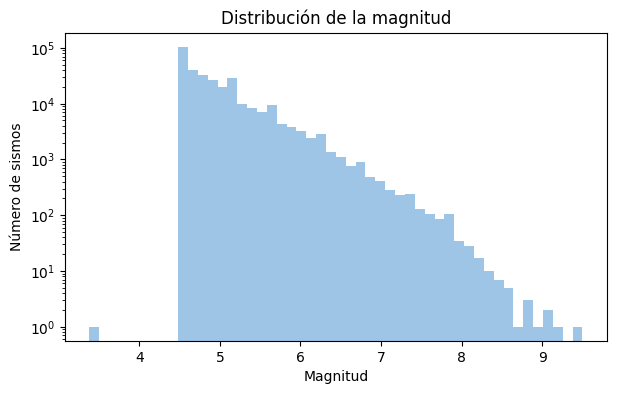

In [ ]:

#para obtener las estadísticas (como en la tarea 1)
print(df['mag'].describe())
print('Sismos con mag >= 6:', round((df['mag'] >= 6).mean() * 100, 2))


#estetica del gráfico, no son necesarios, pero util para facilitar la visualización :))
plt.figure(figsize=(7, 4))
plt.hist(df['mag'], bins=50, color='#9EC4E6')

#usamos una escala log para una mejor visualización de los datos
plt.yscale('log')

#Comanos para la visualización del grafico
plt.xlabel('Magnitud')
plt.ylabel('Número de sismos')
plt.title('Distribución de la magnitud')
plt.show()

Resultados: media 4.93, mediana 4.8, desviación 0.48, y solo 4,6% de los sismos tiene magnitud ≥ 6 (0,5% ≥ 7).

Análisis/Interpretación: el target está muy concentrado entre 4.5 y 5.1, con cola larga hacia sismos grandes (explicado en la tarea 1 por la ley de Gutenberg-Richter). Esto nos dice que los extremos serán difíciles de predecir. (Menos datos para poder entrenar y probar los modelos)

In [ ]:
# Magnitud promedio según la profundidad
df['prof'] = pd.cut(df['depth'], bins=[-10, 70, 300, 800],
                    labels=['superficial', 'intermedia', 'profunda'])
print(df.groupby('prof', observed=True)['mag'].agg(['count', 'mean', 'median']).round(2))

# Magnitud promedio según período (muestra el sesgo de detección de la Tarea 1)
periodos = pd.cut(df['year'], [1899, 1960, 1990, 2010, 2030])
print(df.groupby(periodos, observed=True)['mag'].agg(['count', 'mean']).round(2))

              count  mean  median
prof                             
superficial  240994  4.95     4.8
intermedia    52729  4.85     4.7
profunda      15371  4.89     4.7
               count  mean
year                      
(1899, 1960]   10549  6.05
(1960, 1990]   73883  5.04
(1990, 2010]  106162  4.88
(2010, 2030]  118500  4.81


In [ ]:
# Features de entrada y target
features = ['depth', 'latitude', 'longitude']
X = df[features]
y = df['mag']

# 80% entrenamiento, 20% test; random_state fijo para que sea reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

# Baseline: predecir siempre la media del conjunto de entrenamiento
pred_base = np.full(len(y_test), y_train.mean())
print('MAE base :', round(mean_absolute_error(y_test, pred_base), 3))
print('RMSE base:', round(np.sqrt(mean_squared_error(y_test, pred_base)), 3))

(247275, 3) (61819, 3)
4.933 4.931
MAE base : 0.353
RMSE base: 0.481


**Definición Problema:**

Queremos predecir la magnitud de un sismo a partir de su ubicación (latitud, longitud, profundidad)

Ya encontramos, a partir de la tarea 1, que hay un sesgo en el catálogo, debido probablemente a la mejora en los sistemas de detección de actividad sismica, lo que generó un aumento considerable en los sismos registrados a partir de la década de los 60s. Ahora queremos saber cuanta información realmente cuanta información sobre la magnitud de un sismo puede predecirse/explicarse por las propiedades fisicas de este. (Por eso mismo no lo utilizamos como feature)

Para este caso trabajamos con un problema de regresión, debido a que la variable de magnitud es una variable continua. Para esto utilizaremmos como features a la profundidad, latitud y longitud (con estas podemos definir donde están localizados los sismos)

Algoritmo a utilizar: Árbol de decisión, ya que logra obtener relaciónes no lineales entre coordenadas, tiene el hiperparámetro de max_depth, que es útil para analizar bias-varianza. Ademas, no requiere escalar las variables a diferencia de kNN, SVM, Gradient descent, lo que es util para los features que estamos utilizando, los cuales están escalados de forma distinta (km, grados), y es mas facil evitar un data leakage cuando sea el ajuste con el train.

In [ ]:
# Modelo base: árbol de regresión con profundidad máxima 5
# random_state fijo para que el resultado sea reproducible
modelo = DecisionTreeRegressor(max_depth=5, random_state=42)

# El modelo aprende solo con los datos de entrenamiento
modelo.fit(X_train, y_train)

print('Hojas:', modelo.get_n_leaves())

Hojas: 32


## Evaluación del modelo base: desempeño en train y en test

**¿Qué vamos a hacer en este paso?**

Vamos a medir qué tan bien predice la magnitud el árbol que entrenamos
(`max_depth=5`). Para eso calcularemos las predicciones en dos conjuntos:

- **Train (80%):** los datos con los que el modelo aprendió.
- **Test (20%):** datos que el modelo nunca vio, y que simulan sismos nuevos.

Comparar ambos es necesario porque el desempeño en train por sí solo no dice si
el modelo aprendió un patrón real o si solo memorizó los datos. La diferencia
entre train y test es la evidencia que usaremos para detectar sobreajuste o
subajuste.

**¿Con qué métricas?**

Como la magnitud es una variable continua, no podemos usar accuracy, precision
ni recall (que sirven para clases). Usaremos las métricas de regresión:

- **MAE:** error absoluto promedio, en unidades de magnitud. Es fácil de
  interpretar: "en promedio el modelo se equivoca en X puntos de magnitud".
- **RMSE:** también en unidades de magnitud, pero al elevar los errores al
  cuadrado penaliza más los errores grandes. Nos interesa porque hay pocos
  sismos grandes y queremos ver si el modelo falla en ellos.
- **R²:** compara el modelo con uno que siempre predice la media. R² = 1 es una
  predicción perfecta, R² = 0 significa que no mejora a la media, y R² < 0 que
  es peor que la media.

Además calcularemos un **baseline** (predecir siempre la media de train). Sin
él, un número como "MAE = 0.33" no se puede interpretar: no sabríamos si es
bueno o malo.

**¿Qué esperamos encontrar y por qué?**

1. **Desempeño similar en train y test.** Limitamos el árbol a `max_depth=5`
   (máximo 32 hojas), así que es un modelo simple con poca capacidad para
   memorizar. Según la clase de bias-varianza (Semana 6), un modelo simple
   tiene varianza baja, y por eso debería rendir parecido en datos nuevos.
2. **Una mejora pequeña sobre el baseline y un R² bajo.** En nuestro EDA, la
   magnitud promedio era casi igual entre rangos de profundidad y de latitud,
   así que esperamos que la ubicación y la profundidad expliquen solo una parte
   pequeña de la magnitud.
3. **Un RMSE mayor que el MAE.** Por la ley de Gutenberg-Richter (Tarea 1) hay
   muchos sismos pequeños y muy pocos grandes, y los errores en estos últimos
   serían grandes y pesarían más en el RMSE.

**¿Qué podría pasar y qué significaría?**

**nota:** Utilizamos IA para poder hacer la siguiente tabla, para mejor claridad y orden :)))

| Resultado posible | Qué significaría |
|---|---|
| Train similar al test, ambos con R² bajo (**lo que esperamos**) | No hay sobreajuste. El modelo es estable, pero limitado: puede ser subajuste, o que las features contengan poca información sobre la magnitud |
| Train mucho mejor que test | Sobreajuste: el modelo memorizó detalles del entrenamiento y no generaliza (varianza alta) |
| R² ≈ 0 o negativo en test | Las features no ayudan a predecir mejor que la media, o el modelo es peor que ella |
| Test mejor que train | Revisar si el split dejó casos más fáciles en test |


In [ ]:
# Función que calcula las tres métricas (de la actividad de la Semana 6)
def evaluar(y_real, y_pred):
    return {
        'R2': round(r2_score(y_real, y_pred), 3),
        'MAE': round(mean_absolute_error(y_real, y_pred), 3),
        'RMSE': round(np.sqrt(mean_squared_error(y_real, y_pred)), 3)
    }

# Predicciones del modelo en ambos conjuntos
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)


resultados = pd.DataFrame({
    'Baseline (media) - test': evaluar(y_test, pred_base),
    'Árbol - train': evaluar(y_train, pred_train),
    'Árbol - test': evaluar(y_test, pred_test)
}).T

resultados

,R2,MAE,RMSE
Baseline (media) - test,-0.000,0.353,0.481
Árbol - train,0.127,0.328,0.450
Árbol - test,0.125,0.327,0.450


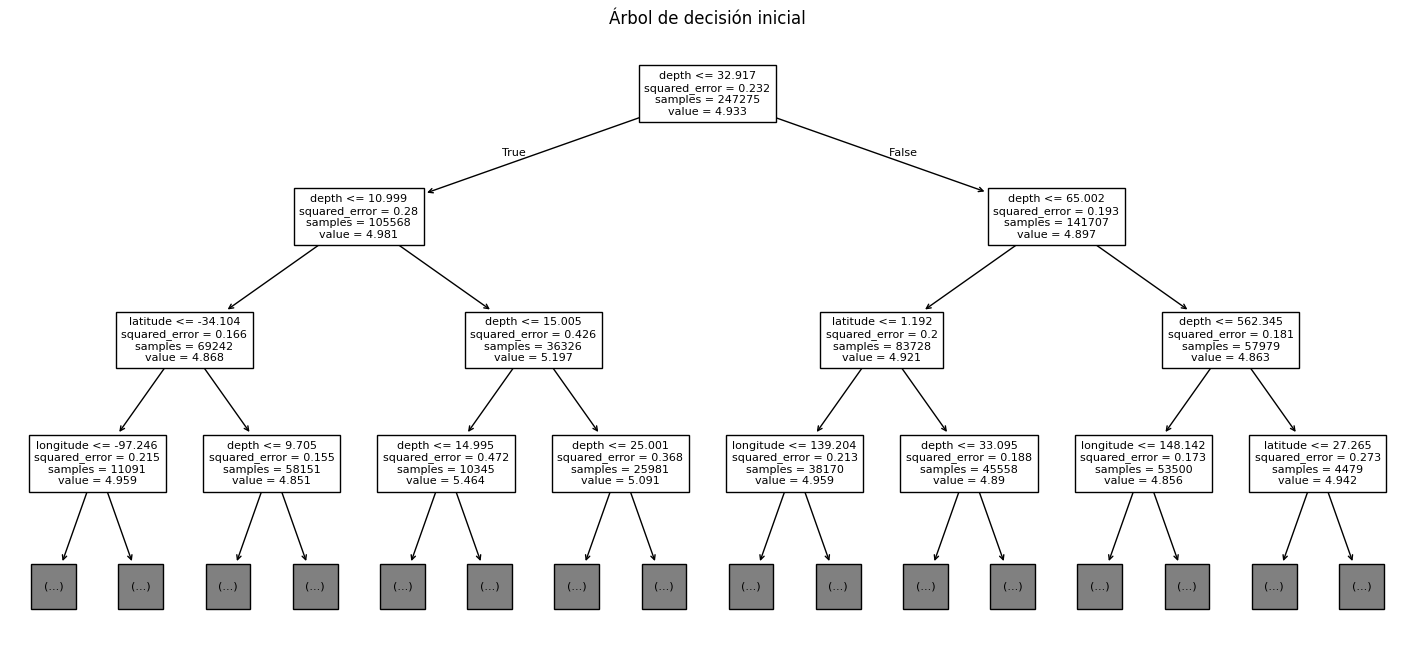

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(modelo, feature_names=features, max_depth=3, filled=False, fontsize=8)
plt.title('Árbol de decisión inicial')
plt.show()

**¿Se cumplieron nuestras expectativas?**

1. **Desempeño similar en train y test: sí.** El R² es 0.127 en train y 0.125 en
   test, y el MAE es 0.328 y 0.327. La diferencia es mínima, por lo que no hay
   indicios de sobreajuste: el modelo rinde igual con datos que no vio. Esto es
   coherente con que limitamos la profundidad a 5, lo que impide que memorice.

2. **Mejora pequeña sobre el baseline y R² bajo: sí.** Respecto a predecir
   siempre la media, el MAE baja de 0.353 a 0.327 y el RMSE de 0.481 a
   0.450. El R² de 0.125 nos dice que la profundidad y la ubicación explican
   cerca de un 12,5% de la variabilidad de la magnitud. El R² del baseline es
   prácticamente 0, lo que confirma que es un punto de
   referencia correcto.

3. **RMSE mayor que MAE. El RMSE
   siempre es mayor o igual al MAE por definición, y el baseline también tiene
   esa diferencia (0.481 vs 0.353). Si realmente fallamos más en los sismos
   grandes lo veremos recién en el análisis de errores, separando por rango de
   magnitud.

**¿Qué significa?**

- El modelo es estable pero limitado. Que train y test sean casi iguales
  descarta el sobreajuste, pero un R² bajo en ambos conjuntos puede tener dos
  explicaciones: El modelo es demasiado simple (subajuste, bias alto), o
  la ubicación y la profundidad contienen poca información sobre la
  magnitud. Con una sola evaluación no podemos distinguir cuál de las dos es.
  Eso es lo que investigaremos en el experimento variando `max_depth`.
- La mejora es real pero insuficiente en términos prácticos. La mayoría de los
  sismos está entre magnitud 4.5 y 5.1, por lo que un error promedio de 0.33
  es una fracción importante de ese rango. El modelo sirve para entender qué
  parte de la magnitud se asocia a la ubicación, pero no para predecir la
  magnitud de un sismo.
- Este resultado conecta con la Tarea 1: la señal física existe pero es débil, y
  gran parte de lo que determina la magnitud no está en estas features

## Experimento: ¿cómo cambia el modelo al variar la profundidad máxima del árbol?

**¿Qué vamos a modificar?**

Solo el hiperparámetro `max_depth` (profundidad máxima del árbol). Todo lo demás
se mantiene igual: mismas features (`depth`, `latitude`, `longitude`), mismo
split train/test (80/20, `random_state=42`) y mismas métricas. Así, cualquier
cambio en el desempeño se debe únicamente a la profundidad.

Probaremos `max_depth` = 1, 2, 3, 5 (modelo base), 8, 12, 16 y sin límite.

**¿Por qué este hiperparámetro?**

`max_depth` controla la complejidad del modelo: más profundidad permite más
cortes y por tanto más hojas (con profundidad p hay como máximo 2^p hojas). Es
el ejemplo típico del balance entre sesgo y varianza visto en la Semana 6.

**Predicción**

- **Profundidad baja (1 a 3): subajuste.** Con pocos cortes, el modelo es
  demasiado simple para capturar las diferencias regionales (sesgo alto). Esperamos
  R² bajo y parecido en train y test, porque el modelo no tiene capacidad de
  memorizar.
- **Profundidad intermedia: mejora en test hasta un punto.** Al agregar niveles,
  el árbol puede separar más regiones y profundidades, así que esperamos que el
  desempeño en test mejore respecto al modelo base, aunque no mucho, dado el
  R² bajo del base.
- **Profundidad alta: sobreajuste.** El R² en train debería seguir subiendo (el
  árbol aprende cada vez más detalles de los datos de entrenamiento), mientras
  el R² en test debería estancarse y luego **empeorar** (varianza alta). Sin
  límite de profundidad, esperamos que el árbol memorice casi cada sismo del
  entrenamiento (R² train ≈ 1) y que en test sea muy malo, posiblemente peor que
  predecir la media (R² < 0).
- **Forma general esperada:** una curva de test con un máximo en profundidad
  intermedia, y una brecha train-test que se ensancha con la profundidad. Es la
  curva en U del error de test vista en clases.

**¿Qué significaría cada resultado?**

| Resultado posible | Qué significaría |
|---|---|
| El test mejora claramente más allá de la profundidad 5 | El modelo base tenía subajuste: le faltaba flexibilidad |
| El test casi no mejora y luego empeora | La información en latitud, longitud y profundidad es limitada: el problema está en las features más que en el modelo |
| El test sigue mejorando con más profundidad | Habría patrones regionales más finos que aprovechar (lo que sería inesperado por el R² bajo del base) |

In [ ]:
# Profundidades a probar (None = el árbol crece sin límite)


profundidades = [1, 2, 3, 5, 8, 12, 16, None]


#Considerar que antes ibamos a correr el codigo cada vez para ir probando cada valor
#pero con ayuda de IA nos dio una corma de correr todos los valores con un ciclo


filas = []
for p in profundidades:
    # Usamos mismo algoritmo, features y split; solo cambia max_depth
    m = DecisionTreeRegressor(max_depth=p, random_state=42)
    m.fit(X_train, y_train)

    pred_tr = m.predict(X_train)
    pred_te = m.predict(X_test)


#Tabla para mejorar la visualizacion de los datos
    filas.append({
        'max_depth': 'sin límite' if p is None else p,
        'hojas': m.get_n_leaves(),
        'R2 train': round(r2_score(y_train, pred_tr), 3),
        'R2 test': round(r2_score(y_test, pred_te), 3),
        'MAE train': round(mean_absolute_error(y_train, pred_tr), 3),
        'MAE test': round(mean_absolute_error(y_test, pred_te), 3),
        'RMSE train': round(np.sqrt(mean_squared_error(y_train, pred_tr)), 3),
        'RMSE test': round(np.sqrt(mean_squared_error(y_test, pred_te)), 3)
    })

resultados_exp = pd.DataFrame(filas)
resultados_exp

,max_depth,hojas,R2 train,R2 test,MAE train,MAE test,RMSE train,RMSE test
0,1,2,0.007,0.008,0.353,0.351,0.480,0.479
1,2,4,0.054,0.053,0.345,0.343,0.469,0.468
2,3,8,0.076,0.078,0.339,0.337,0.463,0.462
3,5,32,0.127,0.125,0.328,0.327,0.450,0.450
4,8,242,0.162,0.151,0.321,0.321,0.441,0.443
5,12,2584,0.231,0.136,0.306,0.321,0.423,0.447
6,16,14791,0.377,0.028,0.268,0.332,0.380,0.474
7,sin límite,202785,1.000,-0.560,0.000,0.414,0.007,0.600


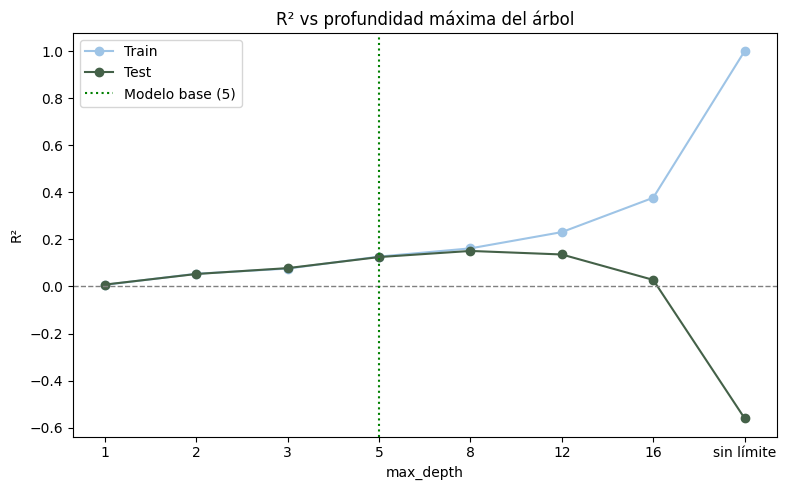

In [ ]:
# Figura: R² en train y test según la profundidad
x = range(len(resultados_exp))

plt.figure(figsize=(8, 5))
plt.plot(x, resultados_exp['R2 train'], marker='o', color='#9EC4E6', label='Train')
plt.plot(x, resultados_exp['R2 test'], marker='o', color='#446148', label='Test')
plt.axhline(0, color='gray', linestyle='--', linewidth=1)   # R² = 0: igual que predecir la media
plt.axvline(list(resultados_exp['max_depth']).index(5), color='green',
            linestyle=':', label='Modelo base (5)')
plt.xticks(x, resultados_exp['max_depth'])
plt.xlabel('max_depth')
plt.ylabel('R²')
plt.title('R² vs profundidad máxima del árbol')
plt.legend()
plt.tight_layout()
plt.show()

**Confirmación de los números obtenidos**

Las limitaciones del experimento anterior (elegir la profundidad mirando el test, y probar solo max_depth) motivan el uso de `GridSearchCV`. Esta herramienta busca los mejores hiperparametros con validacion cruzada sobre el conjunto de entrenamiento, dejando el test intacto para la evaluacion final. Variamos la profundidad maxima `max_depth`, el mínimo de sismos por hoja `min_samples_leaf` y el mínimo de muestras para dividir un nodo `min_samples_split`, para comprobar si las conclusiones anteriores se mantienen cuando el modelo se elige de forma mas rigurosa.

In [ ]:
#Confirmamos la conclusión y los números obtenidos.
from sklearn.model_selection import GridSearchCV
model_1 = DecisionTreeRegressor(random_state = 42)

param_grid = {
    'max_depth': [1, 2, 3, 5, 8, 12, 16, None],
    'min_samples_leaf': [1, 5, 20, 50, 100, 200, 500], #En un inicio se optó por 100 y se tuvo que aumentar para verificar
    'min_samples_split': [2, 10, 50]
}

grid = GridSearchCV(estimator = model_1, param_grid = param_grid, cv = 5, scoring = 'r2', return_train_score = True)
grid.fit(X_train, y_train)

print('Mejores Parametros: ', grid.best_params_)

Mejores Parametros:  {'max_depth': 12, 'min_samples_leaf': 100, 'min_samples_split': 2}


In [ ]:
#Calculamos los errores.
mejor_modelo = grid.best_estimator_
for nombre, X_, y_ in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
  pred = mejor_modelo.predict(X_)
  print(f'-{nombre}-')
  print('R2: ', round(r2_score(y_, pred), 3))
  print('MAE: ', round(mean_absolute_error(y_, pred), 3))
  print('MSE: ', round(mean_squared_error(y_, pred), 3))
  print('RMSE: ', round(np.sqrt(mean_squared_error(y_, pred)), 3))

-Train-
R2:  0.187
MAE:  0.315
MSE:  0.189
RMSE:  0.434
-Test-
R2:  0.16
MAE:  0.319
MSE:  0.194
RMSE:  0.441


**¿Se cumplió la predicción?** En su forma general, sí.

- **Subajuste (profundidad 1 a 3):** train y test son casi idénticos y con R² muy bajo (0.008 con un solo corte). Con 2 hojas el modelo apenas mejora a predecir la media. Cada nivel adicional mejora ambos conjuntos, lo que indica que ahí el modelo aún era demasiado simple (sesgo alto).
- **Mejor desempeño en test: profundidad 8.** El R² test llega a 0.151 y el MAE a 0.321, algo mejor que el modelo base (0.125 y 0.327). La mejora existe, pero es pequeña.
- **El sobreajuste aparece desde la profundidad 12.** El R² de train sigue
  subiendo (0.231) mientras el de test baja (0.136), y la brecha crece, En 16 es
  de 0.349 (0.377 vs 0.028).
- **Sin límite: memorización.** El árbol llega a 64 niveles y 202.785 hojas
  (casi una por cada sismo de entrenamiento). Logra R² = 1 y error casi cero en
  train, pero en test el R² es −0.560 y el MAE (0.414) es peor que el del
  baseline (0.353): el modelo es peor que predecir la media.
- La figura muestra la curva típica de bias-varianza de la Semana 6: el error de
  test mejora con la complejidad, alcanza un óptimo intermedio y luego
  empeora, mientras el de train solo mejora.

**¿Qué podemos concluir?**

1. Respondemos la duda que quedó abierta al evaluar el modelo base: había
   **un poco de subajuste** (con más profundidad el test mejoró de 0.125 a
   0.151). Aun en su mejor punto, el árbol
   explica solo ≈15% de la variabilidad de la magnitud, y a partir de la
   profundidad 12 empieza a memorizar. Esto sugiere que el principal límite está
   en la poca información de las tres features, más que en la flexibilidad del
   modelo.
2. Un modelo más complejo no es mejor. Si miráramos solo el R² de train,
   elegiríamos el árbol sin límite, que es el peor en datos nuevos. Por eso
   evaluar siempre en test es importante para este caso.
3. Las métricas no reaccionan igual: entre profundidad 8 y 12 el MAE de test
   se mantiene en 0.321, pero el RMSE y el R² empeoran (0.443 a 0.447 y
   0.151 a 0.136). El MAE es menos sensible a los errores grandes, y
   por eso mirar una sola métrica puede ocultar el sobreajuste.

**Limitaciones del experimento**

- La mejor profundidad (8) se eligió mirando el test, así que su R² de 0.151 es
  algo optimista. Un procedimiento más riguroso usaría un conjunto de validación o
  validación cruzada (actividades de las Semanas 4 y 5), para dejar el test intacto.
- Es un solo split aleatorio con `random_state=42`; otra partición podría dar
  cifras algo distintas. Además, las réplicas de un mismo terremoto pueden
  quedar repartidas entre train y test, lo que favorece el test.
- Elegimos `max_depth=5` para el modelo base antes de este experimento. El
  resultado muestra que 8 habría rendido algo mejor, pero no cambia la conclusión principal.

##Bobliografía

- The pandas development team. (s. f.). *pandas documentation*.
  https://pandas.pydata.org/docs/
  Para `read_csv`, `cut`, `groupby`


- The Matplotlib development team. (s. f.). *Matplotlib: pyplot API*.
  https://matplotlib.org/stable/api/pyplot_summary.html (`hist`, `scatter`,
  `plot`, `axhline`, `axvline`).


- scikit-learn developers. (s. f.). *scikit-learn user guide and API reference*.


  - Métricas de regresión (R², MAE, MSE): https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
  - Guía de árboles de decisión: https://scikit-learn.org/stable/modules/tree.html